# 结构化输出：让程序稳定读取模型结果


## 为什么回答正确，程序却不好处理？

模型回答“张三是一名 30 岁的软件工程师”，人能看懂，程序却需要从句子里提取姓名、年龄与职业。如果模型换了说法，靠字符串切割的处理逻辑就可能失效。

结构化输出让模型按预定义字段返回数据，例如：

~~~json
{
  "name": "张三",
  "age": 30,
  "occupation": "软件工程师"
}
~~~

它适合表单抽取、评论分类、客服工单、文档录入和工作流状态传递。核心目标是：**把自然语言输入转成程序可以按字段读取的数据。**

本篇根据尚硅谷第 06 章的 35 页课件整理，沿用前面的分节排版。所有代码只作阅读示例，放在 Markdown 代码块中，不执行代码或调用模型服务。


## 先分清三个问题：语法、结构与事实

| 层次 | 检查什么 | 例子 |
| --- | --- | --- |
| JSON 语法 | 是否能解析为数据 | 引号、逗号、括号是否正确 |
| Schema 与校验 | 字段、类型、取值是否合规 | age 是整数，评分在 0 到 10 之间 |
| 业务与事实 | 数据是否来自输入且符合实际 | 原文没有年龄，不能自行填成 30 |

`json.loads()` 成功，只能说明文本是合法 JSON；它可能缺字段，也可能给错类型。Pydantic 校验成功，可以说明符合指定规则，但无法自动证明模型没有编造内容。

课件里不同模型把负价格改为正数，或把未知年龄填成 0，正好说明：格式与字段约束能影响生成结果，却不能替代事实核对。信息抽取任务应明确“只依据原文，未知填 null”。


## 手工处理与 with_structured_output

传统处理常要自己要求 JSON、解析文本、校验字段，再创建业务对象：

~~~text
提示词要求 JSON → 模型生成文本 → json.loads → 校验字段 → 创建对象
~~~

`with_structured_output()` 把 Schema 交给模型集成，并连接输出解析；使用 Pydantic 时，还会将结果交给 Pydantic 校验、实例化：

~~~text
定义 Schema → 选择模型支持的输出方式 → 调用模型 → 解析 → 校验 / 返回结果
~~~

它通常返回一个可调用的 Runnable 包装，而不是直接产生结果，也不表示原 `model` 已被永久修改。真正生成结果的是后续的 `.invoke()`。

没有结构化接口的模型，也可以自己用提示词与解析器搭建流程。不能假定所有集成在不支持时都会自动回退；可能在创建包装或调用阶段直接报错。


## 两个维度：Schema 写法与生成方式

课件讲的“四种模式”主要是四种 **Schema 表达方式**，与 `method` 控制的模型生成机制不是同一个维度。

| Schema 写法 | 常见返回结果 | 客户端校验特点 |
| --- | --- | --- |
| Pydantic `BaseModel` | Pydantic 实例 | 对字段、类型和声明的规则做运行时校验 |
| `TypedDict` | 普通字典 | 类型声明主要服务静态检查，不自动成为运行时校验器 |
| JSON Schema 字典 | 普通字典 | 不能默认认为客户端已按完整 Schema 校验 |
| `dataclass` | 依赖集成；课件返回字典 | 标准 dataclass 本身不按注解校验类型，直接支持范围也依赖版本 |

不同集成可能支持不同 Schema 输入。下面的主线用 Pydantic；TypedDict 与 JSON Schema 用于对比；dataclass 小节给出显式转换方式。

Pydantic 实例用 `result.name` 读取字段，字典用 `result["name"]`。不要把“返回结构化数据”统一理解为返回一条 AIMessage。


## 本章模型配置与 method 选择

按课件的 OpenAI 兼容服务方式配置，模型需要支持相应的工具调用或结构化输出能力：

~~~bash
uv add langchain langchain-openai python-dotenv pydantic typing-extensions
~~~

~~~dotenv
CLOSEAI_API_KEY=你的模型服务密钥
CLOSEAI_BASE_URL=服务商提供的OpenAI兼容API地址
CHAT_MODEL=账户可用且支持相应输出方式的模型名称
~~~

~~~python
import os
from dotenv import load_dotenv
from langchain.chat_models import init_chat_model

load_dotenv()
model = init_chat_model(
    model=os.environ["CHAT_MODEL"],
    model_provider="openai",
    api_key=os.environ["CLOSEAI_API_KEY"],
    base_url=os.environ["CLOSEAI_BASE_URL"],
)
~~~

本文在 OpenAI 兼容集成的主线示例中显式写 `method="function_calling"`，方便与第 05 章工具协议衔接，也避免依赖不同版本的默认方式。其他模型集成的参数不一定相同。

| 常见 method | 机制 | 不能误解为 |
| --- | --- | --- |
| `function_calling` | 用函数 / 工具调用参数承载结构化数据 | 需要应用执行一个真实业务函数 |
| `json_schema` | 使用供应商原生 Schema 输出接口 | 所有兼容网关都支持同样约束 |
| `json_mode` | 要求生成合法 JSON，提示词仍需说明目标字段 | 自动按完整 Schema 保证字段与类型 |

`strict` 的支持、可用 Schema 子集与默认 method 都取决于集成和供应商。课件里某个服务的行为是当时的环境观察，不能作为所有版本的固定结论。


## Pydantic 基本用法：定义 Person，再获得实例

从第 05 章继续使用 `BaseModel` 与 `Field`，这次定义的是**模型输出**，不是工具输入。

~~~python
from pydantic import BaseModel, Field

class Person(BaseModel):
    """从给定文本提取的人物信息。"""
    name: str = Field(description="原文中的姓名")
    age: int = Field(description="原文中明确出现的年龄", ge=0, le=150)
    occupation: str = Field(description="原文中的职业")

structured_model = model.with_structured_output(Person, method="function_calling")
person = structured_model.invoke("只依据原文提取：张三是一名30岁的软件工程师。")

print(type(person).__name__)  # 正常解析成功时为 Person
print(person.name)
print(person.age)
print(person.occupation)
~~~

模型返回的是原始协议响应，LangChain 将其解析并交给 Pydantic，最终交给应用的是 Person 实例。此时通常不能写 `person.content`，要读取定义好的字段。

字段描述帮助模型理解含义；类型和 Field 约束用于校验。即便 description 很清楚，也仍需要检查真实结果。


## Pydantic 结果怎样交给后续程序？

Pydantic 对象方便点出字段，传给接口、存入文档或交给其他代码时，可以转成字典或 JSON 文本。

~~~python
data = person.model_dump()
json_text = person.model_dump_json()

print(data["name"])
print(json_text)
~~~

| 方法 | 返回值 | 用途 |
| --- | --- | --- |
| `model_dump()` | Python 字典 | 继续用 Python 处理 |
| `model_dump(mode="json")` | 字典，值转换为可 JSON 序列化的形式 | 包含枚举、日期等字段时 |
| `model_dump_json()` | JSON 字符串 | 传输或保存文本 |
| `model_json_schema()` | 描述字段的 Schema 字典 | 看结构，不是看某次生成的数据 |

`Person.model_json_schema()` 是“表单定义”，`person.model_dump()` 是“这张表单里的值”，不要混用。


## 允许 null 与允许省略字段不同

Pydantic 2 中，`int | None` 或 `Optional[int]` 表示值可以是 None；没有默认值时，字段仍需要出现。

~~~python
from pydantic import BaseModel, Field

class PersonWithUnknownAge(BaseModel):
    name: str = Field(description="姓名")
    age: int | None = Field(description="年龄；原文未提供时必须填 null")
    occupation: str = Field(description="职业")

class PersonWithDefaultAge(BaseModel):
    name: str
    age: int | None = None
    occupation: str
~~~

| 字段声明 | 能否传 None | 本地创建对象时能否不传 |
| --- | --- | --- |
| `age: int` | 否 | 否 |
| `age: int | None` | 是 | 否 |
| `age: int | None = None` | 是 | 是，使用默认值 |

用于模型抽取时，可以要求字段始终存在，未知就填 null：

~~~python
extractor = model.with_structured_output(
    PersonWithUnknownAge, method="function_calling"
)
result = extractor.invoke("只依据原文提取，未知年龄填null：张三是一名医生。")
~~~

这样不会用 0 伪装未知年龄。某些原生严格 Schema 接口要求所有字段必填，使用“必填但允许 null”也更容易表达缺失信息；仍需核对供应商支持的 Schema。


## 默认值：只在数据缺少字段时生效

课件用超时、重试与商品库存演示默认值。Pydantic 的默认值是客户端规则，不等于模型一定会省略字段。

~~~python
from pydantic import BaseModel, Field

class AppConfig(BaseModel):
    timeout: int | None = Field(default=30, description="超时秒数")
    retry: bool = Field(default=False, description="是否重试")
    max_attempts: int = Field(default=6, description="最多尝试次数")

missing = AppConfig(retry=True, max_attempts=5)
explicit_null = AppConfig(timeout=None, retry=True, max_attempts=5)

print(missing.timeout)        # 30：字段缺失
print(explicit_null.timeout)  # None：明确给了 null
~~~

如果模型明确生成 `timeout=null`，30 不会覆盖 null；如果模型生成 0，也不会因为默认值是 30 就改为 30。课件中网关返回 0、1 或 None 的差异，需要检查原始输出，而不是认定 Pydantic 的默认值随机变化。

库存等业务字段缺少来源时，默认 100 会掩盖“未知”。做事实抽取优先保留 null，做应用配置则按业务规则设置默认值；两类任务的缺失处理不同。


## Enum 与 Literal：限制分类结果

分类字段不宜自由填写，否则会出现“高”“很急”“紧急”等难以统一处理的值。课件以紧急程度为例，可以使用枚举：

~~~python
from enum import Enum
from pydantic import BaseModel, Field

class Priority(str, Enum):
    LOW = "低"
    MEDIUM = "中"
    HIGH = "高"

class TaskInfo(BaseModel):
    title: str = Field(description="任务标题")
    priority: Priority = Field(description="根据任务描述判定的紧急程度")

task_model = model.with_structured_output(TaskInfo, method="function_calling")
task = task_model.invoke("提取任务：服务完全不可用，需要立即处理。")
print(task.priority.value)
~~~

只有少数固定选项时，也可以用 `Literal`：

~~~python
from typing import Literal
from pydantic import BaseModel

class TaskInfoLiteral(BaseModel):
    title: str
    priority: Literal["低", "中", "高"]
~~~

Enum 便于多处复用并拥有成员名称，Literal 写法简短。它们约束合法取值；具体怎样判断高、中、低，还要给出业务判定规则。


## 课件应用：从客服对话提取客户信息

把客户信息提取到固定字段，可用于工单分类或 CRM 录入。电话用字符串，避免前导零、分隔符等信息被数字转换破坏；未知邮箱用 null。

~~~python
from typing import Literal
from pydantic import BaseModel, Field

class CustomerInfo(BaseModel):
    """仅依据客服对话抽取的客户信息。"""
    name: str = Field(description="客户姓名")
    phone: str = Field(description="客户提供的电话号码")
    email: str | None = Field(description="客户邮箱，未提供时填null")
    issue: str = Field(description="客户反映的问题，不补充未提到的事实")
    urgency: Literal["低", "中", "高"] = Field(description="处理紧急程度")

conversation = """
客服：您好，请问有什么可以帮助您？
客户：我是王小明，电话138-1234-5678，订单一直没发货，很着急！
客服：好的，我帮您查一下。
"""
customer_model = model.with_structured_output(CustomerInfo, method="function_calling")
result = customer_model.invoke(
    "只依据对话提取，缺少邮箱填null。客户明确表达很着急时判为高。\n"
    + conversation
)
print(result.model_dump())
~~~

“未提供”适合在界面显示，数据层的未知值通常用 None 更清晰。结构化输出只抽取信息，不等于已经创建工单或写入 CRM，业务动作仍由应用完成。


## 列表提取：一段文本可以产生多个对象

输出不一定只有一份人物信息。用外层对象包含列表，可以一次抽取多个人物，同时维持明确的顶层结构。

~~~python
from pydantic import BaseModel, Field

class PersonItem(BaseModel):
    name: str = Field(description="姓名")
    age: int = Field(description="明确提供的年龄")

class PersonList(BaseModel):
    people: list[PersonItem] = Field(description="原文提到的人物列表")

people_model = model.with_structured_output(PersonList, method="function_calling")
result = people_model.invoke("只抽取以下信息：张三30岁，李四25岁。")
for person in result.people:
    print(person.name, person.age)
~~~

课件还用 `pros: list[str]`、`cons: list[str]` 表示评论优缺点，用 `items: list[str]` 表示发票商品。声明列表时说明元素类型，比含糊地要求“返回一组内容”更利于下游处理。

没有人物时可以要求返回空列表；不要为凑字段而生成虚构人物。


## 评论分析：字段描述与真正的取值约束

情感、分数与关键词很适合结构化输出。只在 description 写“0 到 1”，并不会自动建立数值范围校验，要同时声明 Field 约束。

~~~python
from typing import Literal
from pydantic import BaseModel, Field

class SentimentAnalysis(BaseModel):
    sentiment: Literal["positive", "negative", "neutral"]
    confidence: float = Field(ge=0, le=1, description="模型对分类的自评把握程度")
    keywords: list[str] = Field(description="支持判断的原文关键词")

sentiment_model = model.with_structured_output(
    SentimentAnalysis, method="function_calling"
)
result = sentiment_model.invoke("分析评论：课程内容很实用，学到了很多知识。")
~~~

模型填写的 confidence 是自评数值，不能直接当成经过统计校准的正确率。

评分抽取也要区分原文与推断：原文明确写“4分”，可直接抽取；原文没有评分而要求模型估计时，要说明评分规则与推断性质。


## 文档抽取：发票金额、日期与商品

课件展示了 OCR 后或文本形式的发票抽取。实际金额与日期还需要业务校验，以下先按原文提取：

~~~python
from pydantic import BaseModel, Field

class Invoice(BaseModel):
    invoice_number: str = Field(description="发票号码")
    date: str = Field(description="发票日期，格式YYYY-MM-DD")
    total_amount: float = Field(description="原文总金额，单位元", ge=0)
    items: list[str] = Field(description="原文列出的商品名称")

invoice_text = """
发票号：INV-2024-001
日期：2024-01-15
总金额：1299.00
商品：商品A，延保服务
"""
invoice_model = model.with_structured_output(Invoice, method="function_calling")
invoice = invoice_model.invoke("只提取原文发票信息：\n" + invoice_text)
~~~

这里 date 仍是字符串，description 中的格式要求不是完整日期校验；需要校验日期时，可在业务层解析或使用合适类型与校验器。金额的精确运算也应按业务要求采用 Decimal 或最小货币单位整数。

结构化接口不会自动 OCR。图像文档需要先经过可用的视觉模型或 OCR，得到可提取的内容。


## 嵌套结构：对象里还有对象和列表

课件用公司地址、电影演员与评论维度演示嵌套。下面以电影资料为例，把演员列表里的每个元素定义成 Actor。

~~~python
from pydantic import BaseModel, Field

class Actor(BaseModel):
    name: str = Field(description="演员姓名")
    role: str = Field(description="饰演的角色")

class MovieInfo(BaseModel):
    title: str = Field(description="电影标题")
    year: int = Field(description="上映年份")
    director: str = Field(description="导演姓名")
    cast: list[Actor] = Field(description="资料中列出的演员与角色")
    rating: float | None = Field(description="资料提供的10分制评分，未知填null")

movie_model = model.with_structured_output(MovieInfo, method="function_calling")
result = movie_model.invoke(
    "只依据资料提取，评分未知填null：盗梦空间，2010年上映，"
    "导演克里斯托弗·诺兰，演员莱昂纳多·迪卡普里奥饰演柯布。"
)
print(result.cast[0].name)
print(result.cast[0].role)
~~~

电影评分会随来源、日期和平台变化，不应把课件中的 9.3、8.8 等日志数值当成固定事实。本例把未知评分保留为 null。

嵌套层数和字段越多，生成与排错越复杂。课件建议尽量控制在三层以内，这是设计经验，不是统一 API 硬性限制；必要时按子任务拆分，再由代码组合。


## 约束与类型转换：Pydantic 并非默认全部严格

Field 可以声明字符串长度、数值范围等规则。下面只演示本地创建对象的校验行为，不涉及模型调用：

~~~python
from pydantic import BaseModel, Field, ValidationError

class UserInfo(BaseModel):
    name: str = Field(min_length=2, max_length=20)
    age: int = Field(ge=0, le=150)

try:
    UserInfo(name="李四", age=200)
except ValidationError as error:
    print(error.errors()[0]["loc"])

converted = UserInfo(name="张三", age="30")
print(converted.age)  # 默认配置通常转换为整数30
~~~

要禁止某个字段的类型转换，可以用 `Field(strict=True)`：

~~~python
class StrictAge(BaseModel):
    age: int = Field(strict=True)

try:
    StrictAge(age="30")
except ValidationError:
    print("字符串年龄不符合严格整数要求")
~~~

本地 Pydantic 的 strict 控制类型转换；模型 API 的 `strict=True` 控制供应商的 Schema 输出约束，是两套不同机制。某些 Field 规则或自定义校验器也不能完整表达为供应商接受的 Schema，仍要在客户端执行。

默认额外字段通常会被忽略；需要拒绝多余字段时，可以在 Pydantic 模型中配置 `extra="forbid"`。


## Pydantic 结构化输出的工作流程

课件的流程图可以用四步理解：

1. 定义 Pydantic 类，写清字段类型与含义。
2. LangChain 将结构转换为模型集成可用的 Schema。
3. 模型按当前支持的方式生成数据。
4. LangChain 解析响应，Pydantic 校验并创建实例。

使用 function_calling 时，数据往往位于工具调用的 `arguments`；使用原生 json_schema 或 JSON 模式时，数据可能位于消息内容或供应商专用响应字段。不是所有模式都把 Schema 作为 Tools 发送。

具体解析器由集成与 method 决定，例如工具参数解析器或 JSON / Pydantic 解析器。不能把课件图中的某个解析器名称当成所有调用都必经的固定类。

解析失败是否自动重试取决于配置与上层流程。单独 `with_structured_output()` 并不保证自动纠错；原生严格输出也仍有拒绝、截断、接口错误及 Schema 不支持等失败情况。

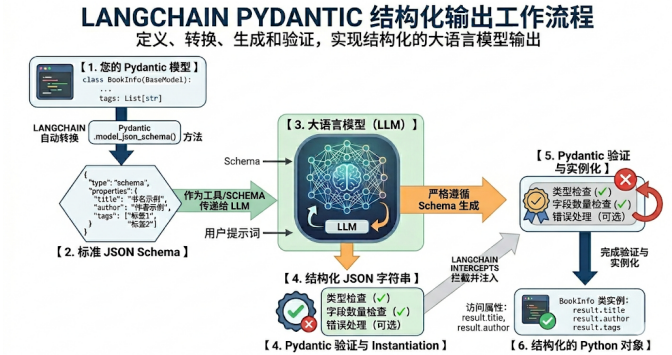

课件图示：定义、转换、生成、校验和返回；具体协议及约束能力以模型集成为准。


## TypedDict：声明字典字段，结果仍是 dict

TypedDict 适合希望得到普通字典的轻量场景。使用 `typing_extensions.TypedDict`，有助于与不同 Python 和校验工具版本兼容。

LangChain 的常见 TypedDict 转换约定中，`Annotated[类型, 默认值, 描述]` 可以提供附加信息；下面的 `...` 表示没有默认值、要求该字段。

~~~python
from typing import Annotated
from typing_extensions import TypedDict

class MovieDict(TypedDict):
    """从原文抽取电影资料。"""
    title: Annotated[str, ..., "电影标题"]
    year: Annotated[int, ..., "上映年份"]
    director: Annotated[str, ..., "导演姓名"]
    rating: Annotated[float | None, ..., "原文评分，未知填null"]

dict_model = model.with_structured_output(MovieDict, method="function_calling")
result = dict_model.invoke(
    "只提取原文，未知评分填null：盗梦空间于2010年上映，导演克里斯托弗·诺兰。"
)
print(type(result).__name__)  # dict
print(result["title"])
~~~

`Annotated` 本身只是类型附加信息容器，不负责校验；默认值与说明怎样解释，由 LangChain 转换逻辑决定。课件的双元素写法与三元素写法可能受转换版本影响，学习时应查看生成的 Schema，别仅凭 IDE 显示判断必填状态。


## TypedDict 的静态检查不等于运行时校验

下面是刻意写错字段的对比示例，静态检查器可能标红，但运行时仍只是一个字典：

~~~python
from typing_extensions import TypedDict

class MovieShape(TypedDict):
    title: str
    year: int

bad_movie: MovieShape = {"title1": "盗梦空间", "year": "2010"}
print(bad_movie)
~~~

这段代码没有因为注解自动检查字段。模型包装返回字典时，也不能仅凭 TypedDict 声明认定已做了 Pydantic 式的本地校验。

若下游依赖字段可靠存在，可再用 Pydantic 模型或 TypeAdapter 显式校验。TypedDict 可以通过 `NotRequired` / `total=False` 表达可省略字段，但转换成模型 Schema 后的支持情况还需核对。

原文缺信息时，优先设计允许 null 的字段或明确可省略规则。不能把“加了 Ellipsis 后某次模型填了空字符串或 0”当成语义正确的缺失处理。


## JSON Schema：直接定义输出协议

需要前后端共享结构或动态生成字段时，可以直接用 JSON Schema 字典。它是一种通用协议，不是天然不适合生产使用；手写时更需要防止漏字段和规则不一致。

~~~python
movie_schema = {
    "title": "MovieRecord",
    "description": "从原文抽取的电影资料",
    "type": "object",
    "properties": {
        "title": {"type": "string", "description": "电影标题"},
        "year": {"type": "integer", "description": "上映年份"},
        "director": {"type": "string", "description": "导演姓名"},
        "rating": {
            "type": ["number", "null"],
            "description": "原文提供的评分，未知填null",
        },
    },
    "required": ["title", "year", "director", "rating"],
    "additionalProperties": False,
}

json_schema_model = model.with_structured_output(
    movie_schema, method="function_calling"
)
result = json_schema_model.invoke(
    "只提取原文，未知评分填null：盗梦空间2010年上映，导演克里斯托弗·诺兰。"
)
print(result["year"])
~~~

传入的是 Python 字典，不是拼接后的 JSON 文本。`title`、`description`、`type`、`properties` 与 `required` 是标准关键字；`additionalProperties=False` 表示不允许未声明字段。

JSON Schema 标准的 title 可以是中文；若集成将其映射为函数或响应格式名称，可能受供应商命名规则限制。示例采用英文标题、中文描述，不能把供应商限制说成 JSON Schema 标准禁止中文。


## 原生 json_schema 与 json_mode 的区别

如果当前 OpenAI 兼容模型与服务确实支持原生 Schema 输出，可以选择：

~~~python
native_model = model.with_structured_output(
    movie_schema, method="json_schema", strict=True
)
~~~

这是供应商原生结构化输出路径，是否支持上述参数与字段，需要核对服务能力。不能仅凭网关能回答普通聊天，就认为它支持该路径。

JSON 模式则需要提示词明确说明字段与缺失信息的表达：

~~~python
json_mode_model = model.with_structured_output(MovieDict, method="json_mode")
result = json_mode_model.invoke(
    "输出JSON对象，包含title、year、director、rating。"
    "只依据原文，未知rating填null：盗梦空间2010年上映，导演克里斯托弗·诺兰。"
)
~~~

JSON 模式主要约束 JSON 格式，不等于原生 Schema 严格约束。原生严格模式也通常只支持 JSON Schema 的一部分，默认值、可选字段、深度与某些校验关键字可能需要调整。

把某个调用改成 `method="json_schema"` 只是在选择协议，不会自动增加客户端完整 JSON Schema 校验。


## JSON Schema 的嵌套数组怎么写？

嵌套对象使用自己的 `properties` 与 `required`，列表使用 `type="array"` 和 `items`。每一层的必填字段需要在自己的对象层声明。

~~~python
cast_schema = {
    "title": "MovieCast",
    "description": "电影标题与演员列表",
    "type": "object",
    "properties": {
        "title": {"type": "string"},
        "cast": {
            "type": "array",
            "items": {
                "type": "object",
                "properties": {
                    "name": {"type": "string"},
                    "role": {"type": "string"},
                },
                "required": ["name", "role"],
                "additionalProperties": False,
            },
        },
    },
    "required": ["title", "cast"],
    "additionalProperties": False,
}
~~~

Pydantic 的 `list[Actor]` 与这里的 `array → items → object` 表达的是同一类结构。手写 Schema 比较长时，可以从 Pydantic 或其他类型定义生成，减少维护两份字段定义的成本。


## dataclass：数据类与校验器不是一回事

标准库 `@dataclass` 自动生成初始化、表示和比较等方法，适合组织数据，但不会仅凭类型注解验证传入值。

~~~python
from dataclasses import dataclass

@dataclass
class MovieData:
    title: str
    year: int
    director: str
    rating: float | None
~~~

课件的集成可以把 dataclass 直接作为输出 Schema，并返回普通字典；这不是所有 `with_structured_output()` 实现都支持的统一行为。直接传入不支持时，可以先转换：

~~~python
from pydantic import TypeAdapter

adapter = TypeAdapter(MovieData)
data_schema = adapter.json_schema()
data_model = model.with_structured_output(data_schema, method="function_calling")
raw_data = data_model.invoke(
    "只提取原文，未知评分填null：盗梦空间2010年上映，导演克里斯托弗·诺兰。"
)
movie = adapter.validate_python(raw_data)
print(movie.title)
~~~

传 Schema 字典时返回字典，显式 TypeAdapter 校验后才得到 MovieData 实例。`MovieData(**raw_data)` 仅构造标准 dataclass，不等于上述校验步骤。

标准 dataclass 的字段默认值和元信息应使用 `dataclasses.field` 等标准写法；不要直接把 Pydantic 的 Field 当成普通数据类的通用默认值机制。


## 课件 fake server：有意返回错误字段

课件用本地假服务绕过真实模型，让客户端收到确定的错误数据，从而观察不同 Schema 的解析与校验行为。

~~~json
{
  "title1": "盗梦空间",
  "year2": 2010,
  "director": "克里斯托弗·诺兰",
  "rating": 9.3
}
~~~

客户端期望的是 `title` 和 `year`，服务却返回 `title1` 和 `year2`。这种人为构造的数据可以稳定检验客户端行为，避免真实模型在生成阶段自己“修好”字段。

在工具调用协议中，数据位于 `tool_calls[].function.arguments`，该字段是 JSON 字符串；LangChain 解析后才变成 `AIMessage.tool_calls[].args` 字典。

假服务没有执行供应商的 Schema 约束。因此这个实验能说明客户端是否校验，不能据此认定真实供应商的原生严格输出完全不约束字段。


### fake server 的精简实现：只模拟工具调用响应

下面保留课件实验的核心，供阅读或以后单独保存为脚本学习。本 Notebook 不启动服务器；这不是完整的模型服务实现。

~~~python
import json
import time
from http.server import BaseHTTPRequestHandler, HTTPServer

class FakeHandler(BaseHTTPRequestHandler):
    def do_POST(self):
        length = int(self.headers.get("Content-Length", "0"))
        request = json.loads(self.rfile.read(length))
        name = request["tools"][0]["function"]["name"]
        wrong_data = {
            "title1": "盗梦空间", "year2": 2010,
            "director": "克里斯托弗·诺兰", "rating": 9.3,
        }
        response = {
            "id": "chatcmpl-test", "object": "chat.completion",
            "created": int(time.time()), "model": "fake-model",
            "choices": [{
                "index": 0,
                "message": {
                    "role": "assistant", "content": "",
                    "tool_calls": [{
                        "id": "call_001", "type": "function",
                        "function": {
                            "name": name,
                            "arguments": json.dumps(wrong_data, ensure_ascii=False),
                        },
                    }],
                },
                "finish_reason": "tool_calls",
            }],
        }
        body = json.dumps(response, ensure_ascii=False).encode("utf-8")
        self.send_response(200)
        self.send_header("Content-Type", "application/json; charset=utf-8")
        self.send_header("Content-Length", str(len(body)))
        self.end_headers()
        self.wfile.write(body)

    def log_message(self, format, *args):
        pass

if __name__ == "__main__":
    HTTPServer(("127.0.0.1", 8889), FakeHandler).serve_forever()
~~~

该服务只接收包含 `tools` 的非流式请求，因此客户端实验要显式使用 `method="function_calling"`。不能直接拿它测试 json_mode 或原生 json_schema 的服务端约束。


## 比较客户端校验：Pydantic 与字典结果

用于假服务实验的 Pydantic 模型要求 title 和 year：

~~~python
from pydantic import BaseModel, Field
from langchain_openai import ChatOpenAI

class MovieRecord(BaseModel):
    title: str = Field(description="电影标题")
    year: int = Field(description="上映年份")
    director: str = Field(description="导演")
    rating: float = Field(description="评分")

fake_model = ChatOpenAI(
    model="fake-model", base_url="http://127.0.0.1:8889/v1", api_key="test-only"
)
checked_model = fake_model.with_structured_output(
    MovieRecord, method="function_calling", include_raw=True
)
bundle = checked_model.invoke("提取电影信息。")
print(bundle["parsing_error"])
~~~

这段客户端示例需要另行启动上一节假服务才能调用；本篇没有实际运行。预期解析会发现 title、year 缺失，并把错误放在 `parsing_error` 中。

| 传入的 Schema | 本实验的典型客户端行为 |
| --- | --- |
| MovieRecord | Pydantic 检查缺失必填字段 |
| TypedDict | 常见字典解析路径返回错误键名字典，没有同等本地类型校验 |
| JSON Schema 字典 | 若没有额外本地校验，可能只完成 JSON 解析 |
| dataclass 转成 Schema 字典 | 先返回字典；显式 TypeAdapter 校验时再发现字段问题 |

不要归纳成“只有 Pydantic 才可能报错”：其他方式仍可能遇到 JSON 解析、接口或供应商 Schema 约束错误，也可以显式加校验器。


## 对字典结果显式做校验

拿到 dict 后，下游仍可以用 Pydantic 模型校验，或用 JSON Schema 校验库验证。与“先定义了 Schema”不同，这是实际执行校验步骤。

~~~python
from pydantic import ValidationError

wrong_data = {
    "title1": "盗梦空间", "year2": 2010,
    "director": "克里斯托弗·诺兰", "rating": 9.3,
}

try:
    movie = MovieRecord.model_validate(wrong_data)
except ValidationError as error:
    print([item["loc"] for item in error.errors()])
~~~

如果项目已有 JSON Schema，可使用 `jsonschema` 等库。这段额外依赖只在需要该校验方式时安装：

~~~bash
uv add jsonschema
~~~

~~~python
from jsonschema import validate

validate(instance=wrong_data, schema=movie_schema)
~~~

正确 Schema 的 `required` 会指出缺少字段，`additionalProperties=False` 会拒绝额外字段。校验失败要决定重新生成、交给人工或返回错误，不能静默把坏数据写入下游系统。


## include_raw：同时保留原始消息与解析结果

默认成功时直接返回解析结果；设置 `include_raw=True` 后，常见模型集成返回包含三项的字典，适合调试与读取用量。

~~~python
structured_model = model.with_structured_output(
    MovieRecord, method="function_calling", include_raw=True
)
bundle = structured_model.invoke(
    "提取原文：示例电影，2020年上映，导演张某，原文评分8.0。"
)

raw = bundle["raw"]
parsed = bundle["parsed"]
error = bundle["parsing_error"]

if error is not None:
    print("解析或校验失败：", error)
elif parsed is None:
    print("没有得到可用的结构化结果，请检查原始响应。")
else:
    print(parsed.title)

print(raw.usage_metadata)
print(raw.response_metadata)
~~~

| 键 | 含义 |
| --- | --- |
| `raw` | 原始 AIMessage，可查看工具调用与用量等信息 |
| `parsed` | 成功解析的对象或字典，失败时通常为 None |
| `parsing_error` | 解析 / 校验错误，成功时为 None |

这是保留解析错误的包装，不是自动重试，也不能吞掉所有网络或认证错误。供应商拒绝请求、网络失败等仍可能直接抛异常；存在 raw 也不代表 parsed 一定可用。


## 输出解析器：没有结构化接口时的替代流程

课件最后介绍“提示词 → 模型 → 解析器”。这种方式主要依赖模型生成合适的文本，仍有解析失败的可能，但对于不支持结构化接口的集成或已有文本流程很有用。

`JsonOutputParser` 返回字典；给它传 Pydantic 类主要用于生成格式说明，不能因此认为结果一定经过完整 Pydantic 校验。需要实例与校验时，使用 `PydanticOutputParser`。

~~~python
from pydantic import BaseModel, Field
from langchain_core.output_parsers import PydanticOutputParser
from langchain_core.prompts import ChatPromptTemplate

class MovieBrief(BaseModel):
    title: str = Field(description="电影标题")
    year: int = Field(description="上映年份")

parser = PydanticOutputParser(pydantic_object=MovieBrief)
prompt = ChatPromptTemplate.from_messages([
    ("system", "只依据用户给出的资料提取。\n{format_instructions}"),
    ("human", "{text}"),
]).partial(format_instructions=parser.get_format_instructions())

chain = prompt | model | parser
result = chain.invoke({"text": "盗梦空间于2010年上映。"})
print(result.title)
~~~

这里的 format_instructions 被真正加入了提示词。只创建解析器，却没告诉模型需要什么格式，会增加失败概率。

解析器不会自动让服务启用原生 Schema 约束。失败时可明确设置重试或纠错流程，不必为了继续运行而直接返回未经校验的原始字符串。


## 三种解析工具：名字接近，职责不同

| 工具 | 典型返回 | 是否按 Pydantic 校验字段 |
| --- | --- | --- |
| `json.loads()` | Python 数据，可能是字典、列表等 | 否 |
| `JsonOutputParser` | 常见为字典 | 不因为传入 pydantic_object 就自动做完整校验 |
| `PydanticOutputParser` | Pydantic 实例 | 是 |
| `with_structured_output(Pydantic类)` | 通常为 Pydantic 实例 | 常见集成会校验；具体流程随 method 变化 |

输出解析器是“响应后怎么读”的组件；供应商原生结构化机制是“生成时怎么约束”的机制。两者可以配合，也不能相互替代。

与第 05 章衔接时还要注意：用 function_calling 实现结构化输出，是把一个结构当成“输出函数”来承载参数，LangChain 直接解析这些参数。它不是查询天气或发送邮件，不需要再执行真实业务工具并回传 ToolMessage。


## 失败时，先找到失败发生在哪一层

| 现象 | 优先检查 |
| --- | --- |
| with_structured_output 不支持 | 模型集成、版本与 Schema 输入类型 |
| 请求被服务拒绝 | method、strict、供应商支持的 Schema 关键字 |
| 必填字段缺失 | 原始输出、可空与默认值声明、必填规则 |
| 解析成功但键名错误 | 是否只做 JSON 解析，是否添加客户端校验 |
| 默认值没有生效 | 模型是否明确生成 null、0 或其他值 |
| 生成值合规但与原文不同 | 提取提示词、字段设计、来源与业务核对 |
| include_raw 后不能点字段 | 先取 bundle 的 parsed，再读取对象属性 |
| JsonOutputParser 返回 dict | 返回类型本来如此，需要实例时改用 PydanticOutputParser |
| 多层嵌套容易失败 | 描述与结构复杂度，是否需要拆分任务 |

可以沿用第 03 章 LangSmith，检查实际 Schema、提示词、工具参数或响应正文。先保留 raw，再定位原因；不要根据“最终字典打印得很整齐”判断数据已经正确。

业务上缺失的信息不要靠默认值或模型猜测补成事实，保留 null 或明确的待处理状态更方便后续流程。


## 本章回顾与面试提示

结构化输出的完整关系是：

~~~text
自然语言资料 + 输出Schema
    ↓ 选择模型支持的生成方式
原始响应（工具参数、JSON内容或专用格式）
    ↓ 解析
字典
    ↓ 客户端校验与实例化（按所选方式）
可交给下游处理的结构化结果
    ↓ 业务与来源检查
符合任务要求的数据
~~~

复习时抓住五点：

1. 四种 Schema 写法与 function_calling、json_schema、json_mode 是两个维度。
2. Pydantic 通常返回实例并校验；TypedDict 与 Schema 字典常返回 dict，需要明确是否额外校验。
3. 允许 null 不等于可以缺字段，默认值也不会覆盖模型明确返回的值。
4. include_raw 保留原始消息、解析结果与解析错误，便于调试，不等于自动纠错。
5. 格式合法、校验通过和事实正确是三个不同要求。

**面试可以这样回答“结构化输出和直接要求 JSON 有什么区别”：** 直接要求 JSON 主要依靠提示词，应用还需要解析和校验。结构化接口把 Schema 交给模型集成，通过工具参数或供应商原生机制生成数据，并连接解析与校验流程；使用哪种约束方式，要看模型能力，事实正确性仍需业务检查。

整理来源：尚硅谷《第 06 章：结构化输出》，讲师宋红康，共 35 页。按课件主线整理，修正了 Optional 与必填规则、默认值、自动回退与重试、TypedDict 和 dataclass 支持范围、JSON Schema 中文标题及解析器校验等说明。示例未实际执行，假服务未启动。

可查阅：[模型文档](https://docs.langchain.com/oss/python/langchain/models)、[结构化输出文档](https://docs.langchain.com/oss/python/langchain/structured-output)、[Pydantic 字段文档](https://docs.pydantic.dev/latest/concepts/fields/)、[JSON Schema 文档](https://json-schema.org/learn)。
